import libraries


In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

data upload


In [9]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')
print("dataset shape:",df.shape)

dataset shape: (7043, 21)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Understand the data

In [10]:
display(df.describe(include="all").T)
print("\\nData types:")
display(df.dtypes)
print("\\nTarget distribution:")
display(df["Churn"].value_counts())
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nData types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


\nTarget distribution:


,count
Churn,
No,5174
Yes,1869


,proportion
Churn,
No,73.46
Yes,26.54


Clean the data

In [11]:
df = df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after TotalCharges conversion:")
display(df.isna().sum().sort_values(ascending=False).head(10))

# Remove the unique customer identifier from model features.
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Unexpected values found in Churn. Inspect df['Churn'].unique().")

print("Target mapping: No = 0, Yes = 1")
print(y.value_counts())

Missing values after TotalCharges conversion:


,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Target mapping: No = 0, Yes = 1
Churn
0    5174
1    1869
Name: count, dtype: int64


Exploratory Data Analysis (EDA)

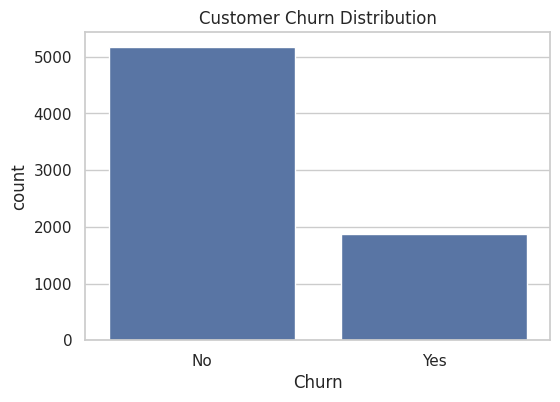

Overall churn rate: 26.54%


In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

churn_rate = (y.mean() * 100)
print(f"Overall churn rate: {churn_rate:.2f}%")

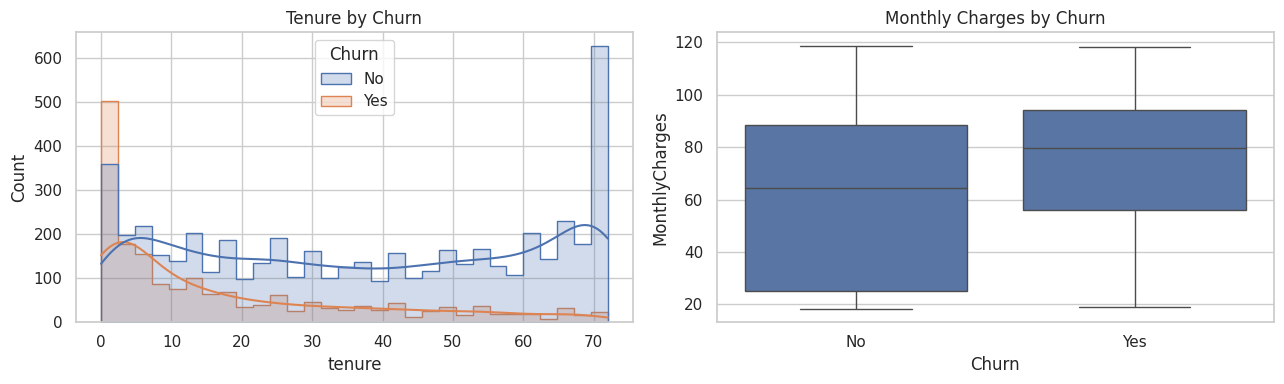

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0], element="step")
axes[0].set_title("Tenure by Churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
plt.tight_layout()
plt.show()

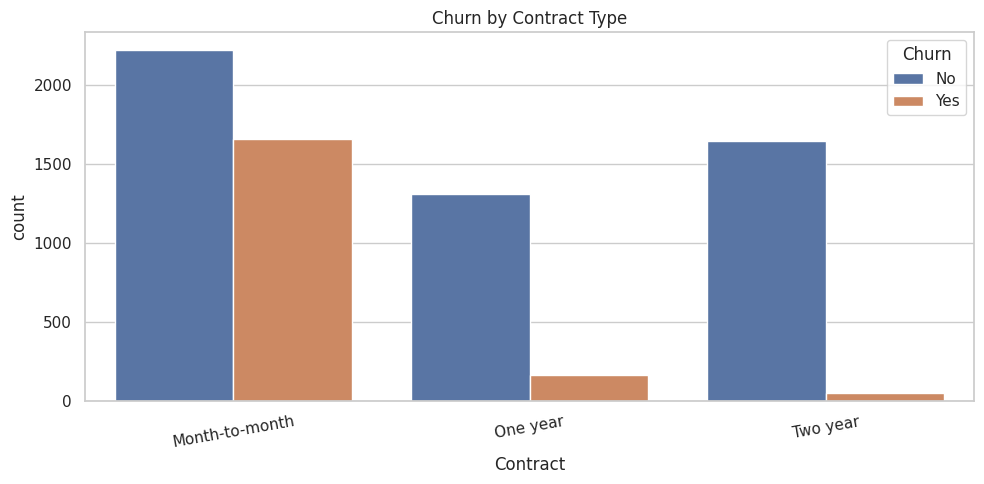

In [14]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

Split into training and test sets

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Training churn proportion:")
display(y_train.value_counts(normalize=True).rename("proportion"))
print("Test churn proportion:")
display(y_test.value_counts(normalize=True).rename("proportion"))

Training rows: 5634
Test rows: 1409
Training churn proportion:


,proportion
Churn,
0,0.734647
1,0.265353


Test churn proportion:


,proportion
Churn,
0,0.734564
1,0.265436


Build preprocessing pipeline

In [16]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


Handle class imbalance with SMOTE

In [17]:
print("Before SMOTE:")
display(y_train.value_counts())

Before SMOTE:


,count
Churn,
0,4139
1,1495


Train Random Forest and XGBoost

In [18]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


Evaluate both models

In [27]:
def evaluate_model(model, X_eval, y_eval, model_name):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision (Churn)": precision_score(y_eval, predictions, zero_division=0),
        "Recall (Churn)": recall_score(y_eval, predictions, zero_division=0),
        "F1 (Churn)": f1_score(y_eval, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities)
    }
    print(f"{model_name} classification report:")
    print(classification_report(y_eval, predictions, target_names=["No Churn", "Churn"], zero_division=0))
    return metrics, probabilities, predictions

rf_metrics, rf_probs, rf_preds = evaluate_model(rf_pipeline, X_test, y_test, "Random Forest")
xgb_metrics, xgb_probs, xgb_preds = evaluate_model(xgb_pipeline, X_test, y_test, "XGBoost")

results = pd.DataFrame([rf_metrics, xgb_metrics]).set_index("Model")
display(results.round(4))

Random Forest classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.84      0.84      1035
       Churn       0.56      0.56      0.56       374

    accuracy                           0.77      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409

XGBoost classification report:
              precision    recall  f1-score   support

    No Churn       0.86      0.84      0.85      1035
       Churn       0.59      0.61      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
Model,,,,,
Random Forest,0.7672,0.5618,0.5588,0.5603,0.8195
XGBoost,0.7821,0.5857,0.6123,0.5987,0.8357


Plot ROC-AUC curves


<Figure size 700x600 with 0 Axes>

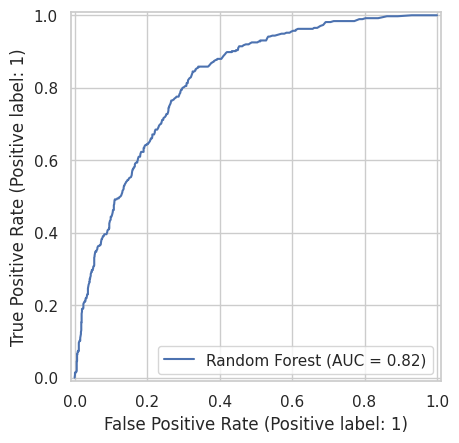

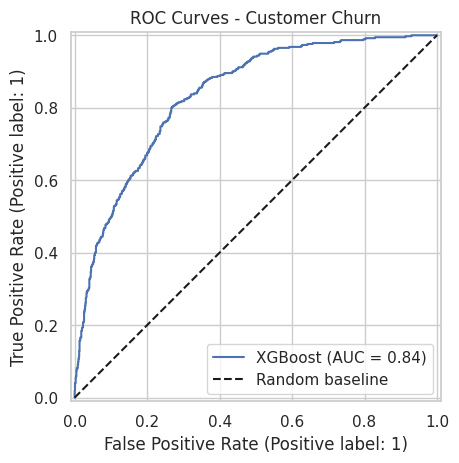

Random Forest ROC-AUC: 0.8195
XGBoost ROC-AUC: 0.8357


In [28]:
plt.figure(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, rf_probs, name="Random Forest")
RocCurveDisplay.from_predictions(y_test, xgb_probs, name="XGBoost")
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.title("ROC Curves - Customer Churn")
plt.legend()
plt.show()

print("Random Forest ROC-AUC:", round(rf_metrics["ROC-AUC"], 4))
print("XGBoost ROC-AUC:", round(xgb_metrics["ROC-AUC"], 4))

Confusion matrices

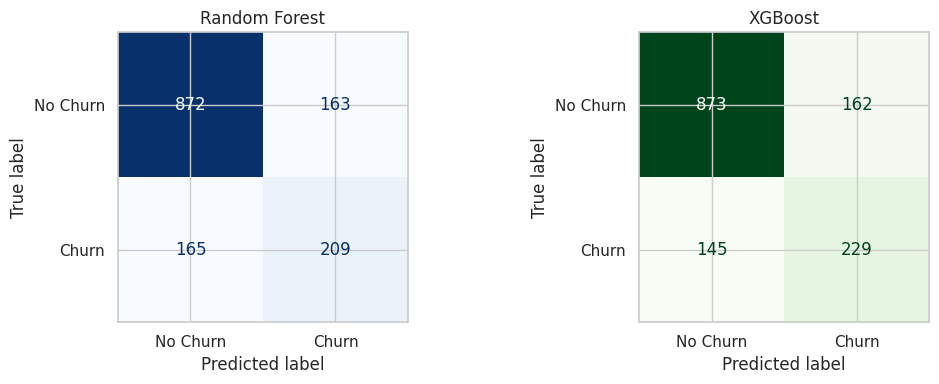

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_preds, display_labels=["No Churn", "Churn"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Random Forest")
ConfusionMatrixDisplay.from_predictions(
    y_test, xgb_preds, display_labels=["No Churn", "Churn"],
    cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("XGBoost")
plt.tight_layout()
plt.show()

Feature importance

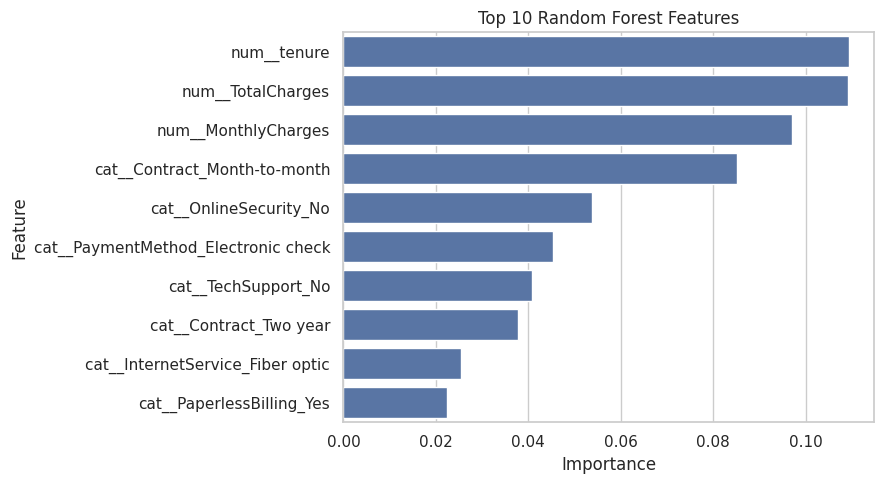

,Feature,Importance
1,num__tenure,0.109320
3,num__TotalCharges,0.109102
2,num__MonthlyCharges,0.096998
36,cat__Contract_Month-to-month,0.085229
18,cat__OnlineSecurity_No,0.053723
43,cat__PaymentMethod_Electronic check,0.045375
27,cat__TechSupport_No,0.040755
38,cat__Contract_Two year,0.037681
16,cat__InternetService_Fiber optic,0.025456
40,cat__PaperlessBilling_Yes,0.022365


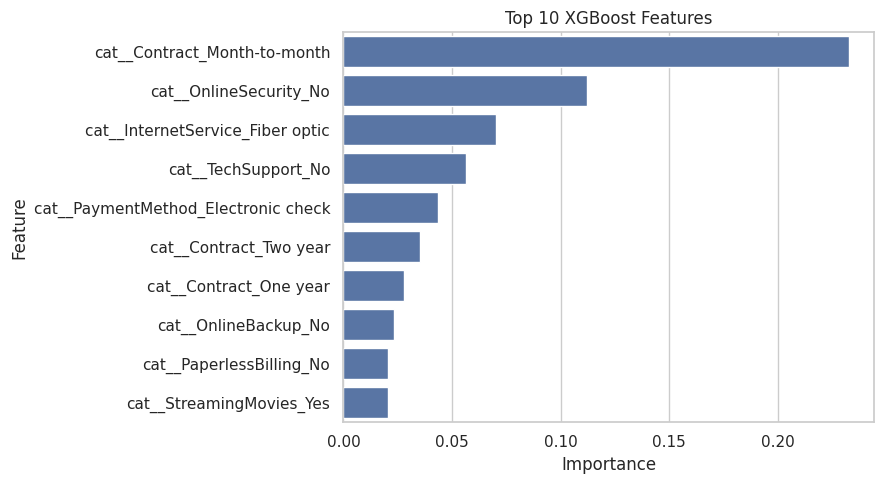

,Feature,Importance
36,cat__Contract_Month-to-month,0.232746
18,cat__OnlineSecurity_No,0.112272
16,cat__InternetService_Fiber optic,0.070341
27,cat__TechSupport_No,0.056380
43,cat__PaymentMethod_Electronic check,0.043735
38,cat__Contract_Two year,0.035429
37,cat__Contract_One year,0.027939
21,cat__OnlineBackup_No,0.023390
39,cat__PaperlessBilling_No,0.020733
35,cat__StreamingMovies_Yes,0.020593


In [30]:
def get_feature_names(fitted_pipeline):
    fitted_preprocessor = fitted_pipeline.named_steps["preprocessor"]
    return fitted_preprocessor.get_feature_names_out()

feature_names = get_feature_names(rf_pipeline)

def plot_top_importances(fitted_pipeline, names, title, top_n=10):
    classifier = fitted_pipeline.named_steps["classifier"]
    importances = classifier.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(top_n)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    display(importance_df)

plot_top_importances(rf_pipeline, feature_names, "Top 10 Random Forest Features")
plot_top_importances(xgb_pipeline, feature_names, "Top 10 XGBoost Features")

Cross-validation ROC-AUC

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)

print(f"Random Forest CV ROC-AUC: {rf_cv_scores.mean():.4f} +/- {rf_cv_scores.std():.4f}")
print(f"XGBoost CV ROC-AUC:       {xgb_cv_scores.mean():.4f} +/- {xgb_cv_scores.std():.4f}")

Random Forest CV ROC-AUC: 0.8177 +/- 0.0118
XGBoost CV ROC-AUC:       0.8408 +/- 0.0101
